# Song Recommender

*Week 10 project for **Gnod**, Ironhack Data Analytics. Andrea Carlo Cerri, November 2026.*

**Gnod** recommends bands based on what similar users like. Jane (CTO) asked for two new kinds of **song** recommendations:

1. **Popular right now:** songs that are hot around the world, whatever the user's taste.
2. **Sounds like your song:** songs that are similar *acoustically* to the one the user picked.

This notebook builds both, from raw data to a working recommender:

| Step | What | Tool |
|---|---|---|
| 1 | Songs that are popular right now, worldwide and in the US | API (Deezer worldwide chart) + web scraping (Billboard Hot 100) |
| 2 | A pool of songs with **audio features** | APIs (Deezer + ReccoBeats) |
| 3 | A first look at the data | pandas, matplotlib |
| 4 | Group songs that sound alike | K-Means clustering (scikit-learn) |
| 5 | What the groups sound like | cluster profiles |
| 6 | The recommender | Python functions |
| 7 | Are the recommendations any good? | hit rate vs a random baseline |
| 8 | Save the results for the app | `data/songs_clustered.csv` → `app.py` (Streamlit) |

**How to run:** open the notebook from the repository folder and run all cells. Steps 1 and 2 only call the website and the APIs if their CSV files are missing in `data/`, so a normal run reads the saved files and takes a few seconds.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             pairwise_distances, silhouette_score)
from sklearn.preprocessing import StandardScaler

DEEZER_CHART_FILE = "data/deezer_chart_worldwide.csv"
BILLBOARD_FILE = "data/billboard_hot100.csv"
SONGS_FILE = "data/gnod_songs_deezer.csv"
HOT100_FEATURES_FILE = "data/hot100_songs_deezer.csv"
POPULAR_FILE = "data/popular_now.csv"
OUTPUT_FILE = "data/songs_clustered.csv"
DEEZER_WAIT = 1          # seconds between Deezer requests (Deezer allows 50 requests every 5 seconds)

## 1. Popular right now

Jane wants songs that are popular **around the world**, so we use two sources: Deezer's worldwide chart (API) and the US Billboard Hot 100 (web scraping).

### 1.1 Worldwide: the Deezer chart (API)

Deezer's free public API needs no account and no key. `chart/0/tracks` returns the current worldwide top 100, with Deezer's own track id, which the app uses to play the song.

In [2]:
class DeezerError(Exception):
    pass


def deezer_get(path, **params):
    """JSON answer of a Deezer endpoint, e.g. deezer_get("search", q="daddy cool")."""
    for attempt in range(5):
        response = requests.get(f"https://api.deezer.com/{path}", params=params)
        time.sleep(DEEZER_WAIT)
        response.raise_for_status()
        data = response.json()
        if "error" not in data:
            return data
        if data["error"].get("code") != 4:      # code 4 = quota full for a few seconds: wait and retry
            raise DeezerError(data["error"])
        time.sleep(5)
    raise DeezerError(data["error"])


# Call the API only if we don't have the file yet (delete it to get today's chart)
if os.path.exists(DEEZER_CHART_FILE):
    deezer_chart = pd.read_csv(DEEZER_CHART_FILE, dtype={"deezer_id": "Int64"})
else:
    tracks = deezer_get("chart/0/tracks", limit=100)["data"]
    deezer_chart = pd.DataFrame({"rank": [t["position"] for t in tracks],
                                 "title": [t["title"] for t in tracks],
                                 "artist": [t["artist"]["name"] for t in tracks],
                                 "deezer_id": [t["id"] for t in tracks]})
    deezer_chart.to_csv(DEEZER_CHART_FILE, index=False)

print(deezer_chart.shape)
deezer_chart.head(10)

(100, 4)


,rank,title,artist,deezer_id
0,1,Dracula (with JENNIE),Tame Impala,3818963601
1,2,Boston,STELLA LEFTY,3895241341
2,3,Choosin' Texas,Ella Langley,3602074142
3,4,Dai Dai,Shakira,4015341011
4,5,Housewife,Tate McRae,4350411742
5,6,BbY WOW,KAROL G,4208859922
6,7,Nicole Kidman,ADÉLA,4250696681
7,8,Patient Zero,Taylor Swift,4304169612
8,9,Stargazing,Myles Smith,2758844701
9,10,hate that i made you love me,Ariana Grande,4045817471


### 1.2 United States: scraping the Billboard Hot 100

The [Billboard Hot 100](https://www.billboard.com/charts/hot-100/) ranks the 100 most popular songs in the US every week. There is no free API for it, so we **scrape** the page: download its HTML with `requests` and pick out the rank, title and artist of every song with `BeautifulSoup`.

- Billboard blocks requests that don't look like a browser (error `403`), so we send a browser **User-Agent**.
- Every song is a `<ul class="o-chart-results-list-row">`: the rank is the first `<span class="c-label">`, the title the `<h3 id="title-of-a-story">`, and the artist the `<span>` right after it.

In [3]:
def scrape_billboard():
    """Rank, title and artist of the 100 songs of the current Billboard Hot 100."""
    headers = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 "
                             "(KHTML, like Gecko) Chrome/120.0 Safari/537.36"}
    response = requests.get("https://www.billboard.com/charts/hot-100/", headers=headers)
    response.raise_for_status()
    soup = BeautifulSoup(response.content, "html.parser")

    rows = []
    for row in soup.select("ul.o-chart-results-list-row"):
        title_tag = row.select_one("h3#title-of-a-story")
        rows.append({"rank": int(row.select_one("span.c-label").get_text(strip=True)),
                     "title": title_tag.get_text(strip=True),
                     "artist": title_tag.find_next_sibling("span").get_text(" ", strip=True)})
    return pd.DataFrame(rows)


# Scrape only if we don't have the file yet (delete it to get this week's chart)
if os.path.exists(BILLBOARD_FILE):
    billboard = pd.read_csv(BILLBOARD_FILE)
else:
    billboard = scrape_billboard()
    billboard.to_csv(BILLBOARD_FILE, index=False)

print(billboard.shape)
billboard.head(10)

(100, 3)


,rank,title,artist
0,1,Choosin' Texas,Ella Langley
1,2,Thriller,Michael Jackson
2,3,Dracula,Tame Impala & JENNIE
3,4,Housewife,Tate McRae
4,5,Boston,Stella Lefty
5,6,Been By Now,Morgan Wallen
6,7,Nicole Kidman,ADELA
7,8,BbY WOW,Karol G With Judeline & rusowsky
8,9,Hate That I Made You Love Me,Ariana Grande
9,10,Stupid Song,Olivia Rodrigo


100 songs, no missing values. Our copy was scraped on **16 November 2026**: the chart still shows Halloween classics (*Thriller*, *Ghostbusters*, *Monster Mash*), a good reminder that "popular right now" changes every week, so in production both charts should be refreshed every week.

### 1.3 One list of popular songs

We put both charts together. To play the Billboard songs in the app we look each one up on Deezer by title and artist. The same song can have slightly different titles in the two charts ("Dracula" on Billboard, "Dracula (with JENNIE)" on Deezer), so we compare titles without the text in brackets.

In [4]:
def clean_title(title):
    """Lower-case title without the text in brackets, e.g. "Dracula (with JENNIE)" -> "dracula"."""
    return pd.Series(title).astype(str).str.replace(r"\s*[\(\[].*?[\)\]]", "", regex=True).str.strip().str.lower()


if os.path.exists(POPULAR_FILE):
    popular = pd.read_csv(POPULAR_FILE, dtype={"deezer_id": "Int64"})
else:
    billboard_ids = []
    for title, artist in zip(billboard["title"], billboard["artist"]):
        results = deezer_get("search", q=f"{title} {artist}", limit=1)["data"]
        billboard_ids.append(results[0]["id"] if results else None)
    popular = pd.concat([deezer_chart.assign(chart="Deezer worldwide"),
                         billboard.assign(chart="Billboard Hot 100 (US)", deezer_id=billboard_ids)],
                        ignore_index=True)
    popular["deezer_id"] = popular["deezer_id"].astype("Int64")
    popular.to_csv(POPULAR_FILE, index=False)

popular["key"] = clean_title(popular["title"]).values
print(popular["chart"].value_counts())
print("Songs in both charts:", popular.groupby("key")["chart"].nunique().eq(2).sum())
popular.head()

chart
Deezer worldwide          100
Billboard Hot 100 (US)    100
Name: count, dtype: int64
Songs in both charts: 19


,rank,title,artist,deezer_id,chart,key
0,1,Dracula (with JENNIE),Tame Impala,3818963601,Deezer worldwide,dracula
1,2,Boston,STELLA LEFTY,3895241341,Deezer worldwide,boston
2,3,Choosin' Texas,Ella Langley,3602074142,Deezer worldwide,choosin' texas
3,4,Dai Dai,Shakira,4015341011,Deezer worldwide,dai dai
4,5,Housewife,Tate McRae,4350411742,Deezer worldwide,housewife


## 2. A pool of songs with audio features: Deezer + ReccoBeats

To find songs that **sound** alike we need numbers that describe the sound of each song: the **audio features** (danceability, energy, loudness, acousticness, tempo...).

**Why not Spotify?** Spotify's API used to give these features, but it no longer does for new developer apps (since November 2024), and in 2026 new apps also need the owner to have Spotify Premium and share a small request quota. So we combined two free APIs that need no account:

| API | Gives us |
|---|---|
| [Deezer](https://developers.deezer.com/api) | songs from public playlists of each genre, with their **ISRC** (the international barcode of a recording) |
| [ReccoBeats](https://reccobeats.com) | the audio features of a song, found by its ISRC |

**Plan:** for 15 genres that sound very different from each other, read the first playlists of the genre on Deezer until we have 100 songs, then ask ReccoBeats for their audio features (40 songs per request). Finally, look up every song's Deezer id by its ISRC, so the app can play it. The genre is only used later, as an answer key to check the clusters: **the model never sees it**.

In [5]:
FEATURES_WAIT = 1        # seconds between ReccoBeats requests
GENRES = ["classical", "jazz", "reggae", "rock", "hip hop", "country", "blues", "soul",
          "salsa", "flamenco", "punk", "folk", "gospel", "bossa nova", "disco"]
SONGS_PER_GENRE = 100
PLAYLISTS_PER_GENRE = 5


def audio_features_by_isrc(isrcs):
    """Audio features from ReccoBeats for up to 40 ISRCs (songs it doesn't know are skipped)."""
    response = requests.get("https://api.reccobeats.com/v1/audio-features", params={"ids": ",".join(isrcs)})
    response.raise_for_status()
    found = {}
    for f in response.json()["content"]:
        found.setdefault(f["isrc"], f)        # the same recording can come back several times: keep the first
    return [found[i] for i in isrcs if i in found]


def add_audio_features(songs_df):
    """Merge the audio features into a DataFrame with an "isrc" column, 40 songs per request."""
    isrcs = songs_df["isrc"].tolist()
    features = []
    for i in range(0, len(isrcs), 40):
        features.extend(audio_features_by_isrc(isrcs[i:i + 40]))
        time.sleep(FEATURES_WAIT)
    if not features:
        return songs_df.iloc[0:0]
    return songs_df.merge(pd.DataFrame(features).drop_duplicates(subset="isrc"), on="isrc", how="inner")


def collect_genre(genre, n_songs):
    """Songs of one genre from Deezer playlists, with their audio features."""
    songs = {}   # isrc -> (song, artist): the same song can be in several playlists
    for playlist in deezer_get("search/playlist", q=genre, limit=PLAYLISTS_PER_GENRE)["data"]:
        for track in deezer_get(f"playlist/{playlist['id']}/tracks", limit=100)["data"]:
            if track.get("isrc") and track["isrc"] not in songs:
                songs[track["isrc"]] = (track["title"], track["artist"]["name"])
        if len(songs) >= n_songs:
            break
    songs_df = pd.DataFrame([(isrc, song, artist, genre) for isrc, (song, artist) in list(songs.items())[:n_songs]],
                            columns=["isrc", "song", "artist", "genre"])
    return add_audio_features(songs_df)


def collect_hot100(billboard):
    """The Billboard songs with their audio features: search each one on Deezer to get its ISRC."""
    isrcs = []
    for title, artist in zip(billboard["title"], billboard["artist"]):
        results = deezer_get("search", q=f"{title} {artist}", limit=1)["data"]
        isrcs.append(results[0].get("isrc") if results else None)
    hot = pd.DataFrame({"isrc": isrcs, "song": billboard["title"], "artist": billboard["artist"], "genre": "hot100"})
    return add_audio_features(hot.dropna(subset=["isrc"]))

In [6]:
# Call the APIs only if we don't have the file yet (the collection takes about 20 minutes)
if os.path.exists(SONGS_FILE):
    songs = pd.read_csv(SONGS_FILE)
else:
    genre_songs = pd.concat([collect_genre(genre, SONGS_PER_GENRE) for genre in GENRES])
    hot100_songs = collect_hot100(billboard)
    hot100_songs.to_csv(HOT100_FEATURES_FILE, index=False)
    songs = pd.concat([genre_songs, hot100_songs]).drop_duplicates(subset="isrc")
    songs.to_csv(SONGS_FILE, index=False)

# ReccoBeats also returns its own id and a link to the song on another platform: we only keep the ISRC
songs = songs.drop(columns=["id", "href"], errors="ignore").reset_index(drop=True)

# Deezer id of every song, to play it in the app (looked up once by ISRC, then read from the file)
DEEZER_IDS_FILE = "data/deezer_ids.csv"
if os.path.exists(DEEZER_IDS_FILE):
    deezer_ids = pd.read_csv(DEEZER_IDS_FILE, dtype={"deezer_id": "Int64"})
else:
    def deezer_id_by_isrc(isrc):
        try:
            return deezer_get(f"track/isrc:{isrc}")["id"]
        except DeezerError:          # Deezer doesn't know this recording
            return None
    deezer_ids = pd.DataFrame({"isrc": songs["isrc"], "deezer_id": [deezer_id_by_isrc(i) for i in songs["isrc"]]})
    deezer_ids.to_csv(DEEZER_IDS_FILE, index=False)
songs = songs.merge(deezer_ids, on="isrc", how="left")
songs["deezer_id"] = songs["deezer_id"].astype("Int64")

print(songs.shape)
print("Songs with a Deezer id:", songs["deezer_id"].notna().sum())
songs.head()

(1207, 16)
Songs with a Deezer id: 1201


,isrc,genre,song,artist,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,deezer_id
0,USSM12004898,classical,"3 Gymnopédies: No. 1, Lent et douloureux",KHATIA BUNIATISHVILI,0.995,0.468,0.00183,0.951,7.0,0.0852,-32.776,1.0,0.0584,75.792,0.1450,1086622472
1,GBAYC9100019,classical,"Bach, JS: Cello Suite No. 1 in G Major, BWV 10...",Mstislav Rostropovich,0.978,0.359,0.11100,0.825,7.0,0.1210,-23.939,1.0,0.0778,91.468,0.6580,3097275
2,GBAYC1702567,classical,Saint-Saëns / Transcr. Vidal: Le carnaval des ...,Gautier Capuçon,0.972,0.213,0.03290,0.926,7.0,0.0978,-28.228,1.0,0.0451,84.819,0.0366,430251032
3,FRZ149013040,classical,"Bagatelle ""A Elise"", WoO 59",Brigitte Engerer,0.993,0.213,0.01100,0.891,9.0,0.0574,-36.453,0.0,0.0398,141.725,0.1820,396891112
4,GBAYC6600267,classical,Beethoven: Piano Sonata No. 14 in C-Sharp Mino...,Daniel Barenboim,0.994,0.165,0.00300,0.913,1.0,0.1500,-42.654,0.0,0.0424,61.201,0.1500,69089334


**1,207 songs** with audio features. Not every song made it: ReccoBeats doesn't know every recording, especially very recent releases, so only **47 of the 100** Billboard songs (genre `hot100`) have features.

## 3. A first look at the data

We use the 9 continuous audio features. `key` and `mode` are left out: they are numbers, but really categories (a musical note from 0 to 11, and major/minor), so a "distance" between them means nothing.

Missing values: 0
Duplicated songs (same ISRC): 0


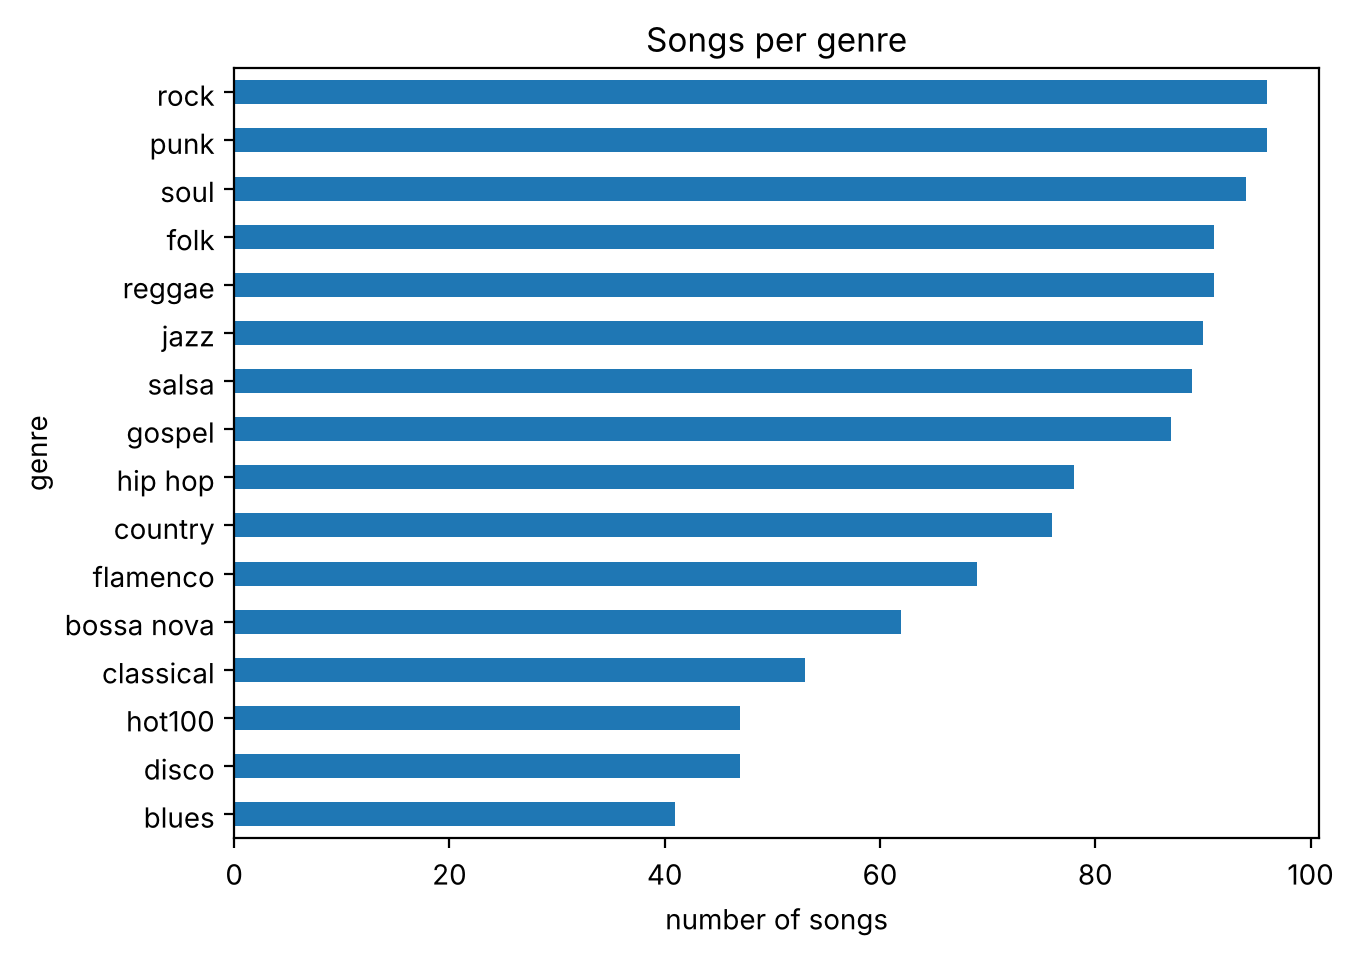

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,1207.00,1207.00,1207.00,1207.00,1207.00,1207.00,1207.00,1207.00,1207.00
mean,0.56,0.53,-9.88,0.07,0.43,0.16,0.17,0.52,119.73
std,0.16,0.25,5.27,0.07,0.35,0.31,0.15,0.26,31.64
min,0.07,0.00,-42.65,0.02,0.00,0.00,0.03,0.00,32.38
25%,0.46,0.34,-12.47,0.03,0.08,0.00,0.09,0.32,92.93
50%,0.57,0.54,-8.61,0.04,0.40,0.00,0.11,0.52,118.01
75%,0.68,0.73,-6.15,0.07,0.77,0.09,0.18,0.73,140.95
max,0.93,0.99,-1.42,0.76,1.00,0.96,0.99,0.98,208.76


In [7]:
FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo"]

print("Missing values:", songs[FEATURES].isna().sum().sum())
print("Duplicated songs (same ISRC):", songs["isrc"].duplicated().sum())

songs["genre"].value_counts().sort_values().plot(kind="barh", figsize=(7, 5), title="Songs per genre")
plt.xlabel("number of songs")
plt.show()

songs[FEATURES].describe().round(2)

- No missing values and no duplicates.
- Genres are not perfectly balanced (41 blues songs, 96 rock songs): ReccoBeats knows some genres better than others. That's fine for clustering, which doesn't use the genre.
- **The features have very different scales:** most go from 0 to 1, but `tempo` goes up to about 200 BPM and `loudness` down to about −40 dB. Clustering is based on distances, so without scaling, tempo and loudness would decide everything. That's why we **scale** them next.

## 4. Grouping songs that sound alike: K-Means

**Clustering** is *unsupervised* learning: there is no right answer to predict, the algorithm finds groups on its own. **K-Means** places *k* centres, gives every song to its nearest centre, moves each centre to the middle of its songs, and repeats until nothing changes. We have to choose *k*.

### 4.1 Scale the features

`StandardScaler` gives every feature a mean of 0 and a standard deviation of 1, so all 9 features count the same.

In [8]:
scaler = StandardScaler()
X = scaler.fit_transform(songs[FEATURES])
X.shape

(1207, 9)

### 4.2 Choose k

We try k = 2 to 10 and look at three quality scores that don't need an answer key:

| Score | Measures | Better |
|---|---|---|
| Silhouette | is each song much closer to its own cluster than to the next one? | higher |
| Calinski-Harabasz | spread *between* clusters vs spread *within* clusters | higher |
| Davies-Bouldin | how much each cluster overlaps with its most similar cluster | lower |

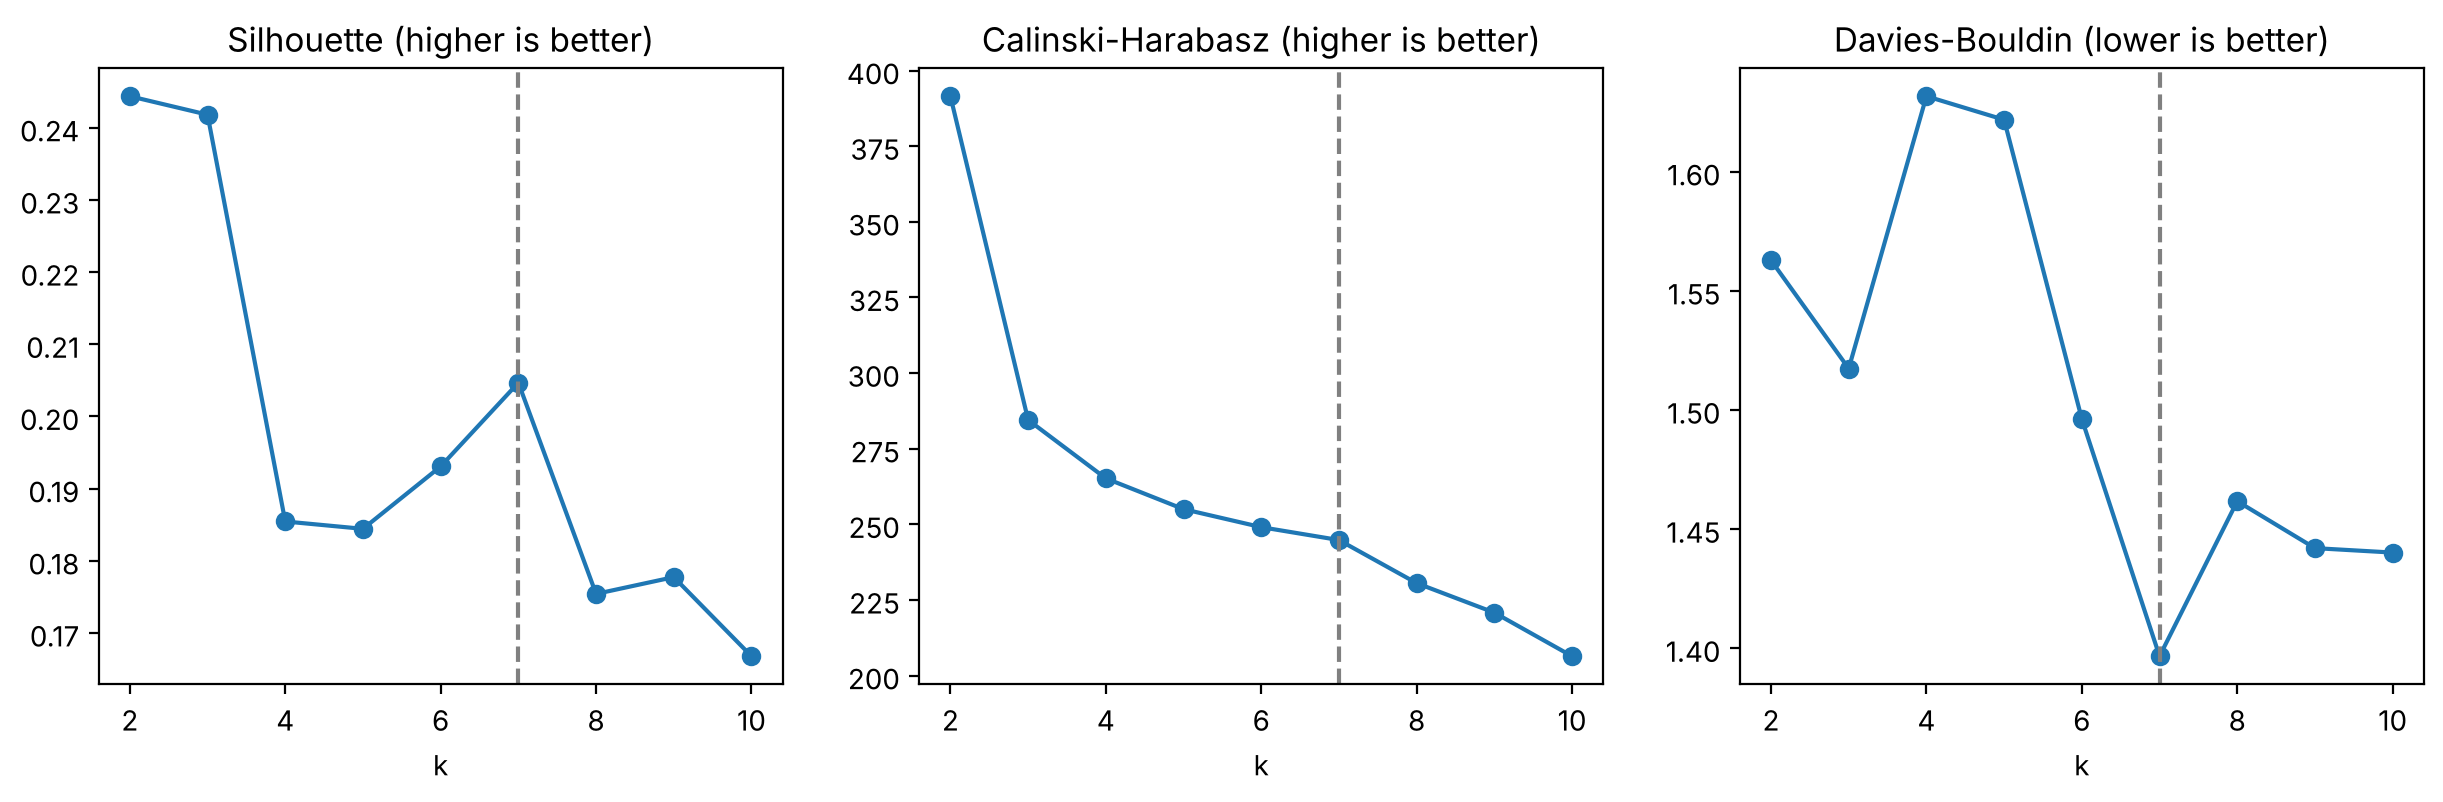

,silhouette,calinski_harabasz,davies_bouldin
k,,,
2,0.244,391.519,1.563
3,0.242,284.533,1.517
4,0.185,265.222,1.632
5,0.184,255.042,1.622
6,0.193,249.091,1.496
7,0.205,244.833,1.397
8,0.175,230.591,1.462
9,0.178,220.835,1.442
10,0.167,206.438,1.440


In [9]:
def cluster_metrics(X, labels):
    """Silhouette, Calinski-Harabasz and Davies-Bouldin, without DBSCAN's noise points (-1)."""
    kept = labels != -1
    return {"silhouette": silhouette_score(X[kept], labels[kept]),
            "calinski_harabasz": calinski_harabasz_score(X[kept], labels[kept]),
            "davies_bouldin": davies_bouldin_score(X[kept], labels[kept])}


k_scores = pd.DataFrame([cluster_metrics(X, KMeans(n_clusters=k, random_state=42).fit_predict(X)) for k in range(2, 11)],
                        index=pd.Index(range(2, 11), name="k"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = {"silhouette": "Silhouette (higher is better)",
          "calinski_harabasz": "Calinski-Harabasz (higher is better)",
          "davies_bouldin": "Davies-Bouldin (lower is better)"}
for ax, (metric, title) in zip(axes, titles.items()):
    ax.plot(k_scores.index, k_scores[metric], marker="o")
    ax.axvline(7, color="grey", linestyle="--")
    ax.set(title=title, xlabel="k")
plt.show()

k_scores.round(3)

**We choose k = 7.**
- Silhouette and Calinski-Harabasz are best at k = 2–3, but 2 or 3 groups are far too coarse to recommend from 15 genres ("loud songs" vs "quiet songs").
- Among the useful values (k ≥ 4), the silhouette peaks at **k = 7** (0.205), and Davies-Bouldin has its **best value of all at k = 7** (1.40).

### 4.3 Compare K-Means with other clustering methods

Next to the scores, two columns tell us whether a clustering is **usable for recommendations**: `noise_%` (songs DBSCAN leaves out, which would get no recommendations) and `largest_%` (if one cluster holds almost every song, "same cluster" means nothing).

In [10]:
K = 7
models = {"K-Means": KMeans(n_clusters=K, random_state=42),
          "Agglomerative (ward)": AgglomerativeClustering(n_clusters=K, linkage="ward"),
          "Agglomerative (complete)": AgglomerativeClustering(n_clusters=K, linkage="complete"),
          "Agglomerative (average)": AgglomerativeClustering(n_clusters=K, linkage="average"),
          "DBSCAN (eps=1.4)": DBSCAN(eps=1.4, min_samples=10)}

has_genre = (songs["genre"] != "hot100").values     # "hot100" is not a genre: leave those songs out of the answer key
rows = []
for name, model in models.items():
    labels = model.fit_predict(X)
    sizes = np.bincount(labels[labels != -1])
    rows.append({"model": name, "n_clusters": len(sizes),
                 "noise_%": (labels == -1).mean() * 100,
                 "largest_%": sizes.max() / sizes.sum() * 100,
                 **cluster_metrics(X, labels),
                 "ARI vs genres": adjusted_rand_score(songs["genre"][has_genre], labels[has_genre])})

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(3)

,n_clusters,noise_%,largest_%,silhouette,calinski_harabasz,davies_bouldin,ARI vs genres
model,,,,,,,
K-Means,7,0.000,27.092,0.205,244.833,1.397,0.117
Agglomerative (ward),7,0.000,31.814,0.169,204.076,1.444,0.120
Agglomerative (complete),7,0.000,43.331,0.134,120.310,1.368,0.053
Agglomerative (average),7,0.000,94.200,0.268,42.233,0.902,0.009
DBSCAN (eps=1.4),5,24.606,90.440,0.123,67.487,1.084,0.027


**We keep K-Means.**
- *Agglomerative (average)* has the best silhouette and Davies-Bouldin, but only because it puts **94%** of the songs in one cluster. *DBSCAN* throws **25%** of the songs away as noise and puts 90% of the rest in one cluster. Both are useless for recommending.
- *K-Means* has no noise, balanced clusters (the biggest holds 27% of the songs), the best Calinski-Harabasz and the best silhouette among the usable models.
- **ARI** (adjusted Rand index) compares the clusters with the genres: 1 = the clusters are exactly the genres, 0 = random. K-Means and ward are the best (≈ 0.12), but still low: the clusters follow the **sound**, not the genre label. That is what Jane asked for.

In [11]:
kmeans = KMeans(n_clusters=K, random_state=42)
songs["cluster"] = kmeans.fit_predict(X)
songs["cluster"].value_counts().sort_index()

cluster
0    244
1    294
2     71
3     63
4     82
5    327
6    126
Name: count, dtype: int64

## 5. What do the clusters sound like?

A cluster is only useful if we can explain it. We look at the average features of each cluster, and then at the genres inside it.

In [12]:
profile = songs.groupby("cluster")[FEATURES].mean().round(2)
profile["songs"] = songs["cluster"].value_counts().sort_index()

# Compare every cluster with the average song: green = above average, red = below
profile.style.background_gradient(cmap="RdYlGn", subset=FEATURES, axis=0).format(precision=2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,songs
cluster,,,,,,,,,,
0,0.45,0.75,-6.13,0.06,0.11,0.02,0.17,0.47,147.42,244
1,0.52,0.32,-12.32,0.05,0.73,0.04,0.13,0.38,112.50,294
2,0.73,0.52,-9.64,0.28,0.31,0.09,0.18,0.68,122.80,71
3,0.51,0.67,-7.92,0.06,0.31,0.04,0.67,0.51,125.13,63
4,0.34,0.12,-22.14,0.04,0.92,0.78,0.12,0.18,102.76,82
5,0.67,0.67,-7.23,0.06,0.28,0.03,0.14,0.74,110.59,327
6,0.65,0.47,-11.50,0.06,0.55,0.79,0.14,0.53,113.31,126


In [13]:
# Names from the profile above. If you rerun this with another version of scikit-learn,
# the cluster numbers can change: check the profile and update the names.
CLUSTER_NAMES = {0: "Loud & fast",
                 1: "Soft & acoustic",
                 2: "Danceable & wordy",
                 3: "Live recordings",
                 4: "Quiet & instrumental",
                 5: "Upbeat & happy",
                 6: "Instrumental grooves"}
songs["cluster_name"] = songs["cluster"].map(CLUSTER_NAMES)

# The answer key: which genres end up in which cluster?
pd.crosstab(songs["cluster_name"], songs["genre"])

genre,blues,bossa nova,classical,country,disco,flamenco,folk,gospel,hip hop,hot100,jazz,punk,reggae,rock,salsa,soul
cluster_name,,,,,,,,,,,,,,,,
Danceable & wordy,3,2,0,2,1,9,0,1,8,2,1,0,37,1,0,4
Instrumental grooves,5,10,1,0,2,6,4,0,49,0,30,0,3,0,13,3
Live recordings,5,5,0,3,2,5,1,14,1,3,2,5,2,5,5,5
Loud & fast,4,0,0,35,11,3,4,39,3,13,2,74,1,39,6,10
Quiet & instrumental,1,1,47,0,0,0,9,0,7,0,10,0,0,1,6,0
Soft & acoustic,12,31,5,6,14,27,68,21,4,7,32,0,1,9,16,41
Upbeat & happy,11,13,0,30,17,19,5,12,6,22,13,17,47,41,43,31


| Cluster | Songs | Sound | Main genres |
|---|---|---|---|
| Loud & fast | 244 | loud, energetic, fastest tempo (147 BPM), not acoustic | punk, rock, country, gospel |
| Soft & acoustic | 294 | quiet, low energy, acoustic, rather sad | folk, soul, jazz, bossa nova, flamenco |
| Danceable & wordy | 71 | most danceable, lots of spoken words, happy | reggae, some flamenco and hip hop |
| Live recordings | 63 | recorded live (liveness 0.67) | mixed, mostly gospel |
| Quiet & instrumental | 82 | very quiet (−22 dB), no vocals, slow, sad | classical, some jazz and folk |
| Upbeat & happy | 327 | danceable, energetic, highest valence | reggae, salsa, rock, soul, country, Hot 100 |
| Instrumental grooves | 126 | danceable but mostly without vocals | hip hop, jazz, salsa |

- A few genres have a clear home: **classical** → quiet & instrumental, **punk** → loud & fast, **folk** → soft & acoustic.
- Others are split by mood: rock, country, soul and reggae have both calm songs and upbeat songs. That's why the clusters match the genres only loosely, and it's the behaviour we want for "sounds like your song".
- **Weak spots:** "Live recordings" groups songs by *how they were recorded*, not by style, and "Upbeat & happy" is a large catch-all.

## 6. The recommender

For the song the user picks:
1. **Is it popular right now?** If its title is in one of the two charts (Deezer worldwide or Billboard Hot 100) → recommend other popular songs.
2. **Otherwise:** find its cluster and recommend the songs **of the same cluster with the closest audio features** (the shortest distance between the scaled features).
3. If the song is not in our database: say so.

In [14]:
D = pairwise_distances(X)                                   # D[i, j] = distance between song i and song j
def is_hot(title, artist=None):
    """True if the title is in today's charts (and, when we know it, by an artist with the same first word)."""
    same_title = popular[popular["key"] == clean_title(title)[0]]
    if artist is None:
        return len(same_title) > 0
    return same_title["artist"].str.lower().str.contains(str(artist).lower().split()[0], regex=False).any()


def similar_songs(i, n=5):
    """The n songs of the same cluster as song i with the closest audio features."""
    same_cluster = np.flatnonzero(songs["cluster"].values == songs["cluster"].values[i])
    same_cluster = same_cluster[same_cluster != i]          # never recommend the song itself
    closest = same_cluster[np.argsort(D[i, same_cluster])[:n]]
    return songs.iloc[closest][["song", "artist", "genre", "cluster_name"]]


def recommend(title, n=5):
    """Gnod's two new features in one function."""
    matches = np.flatnonzero(songs["song"].str.lower() == title.strip().lower())
    artist = songs.loc[matches[0], "artist"] if len(matches) else None

    if is_hot(title, artist):
        print(f"'{title}' is popular right now! Other popular songs:")
        others = popular[popular["key"] != clean_title(title)[0]].drop_duplicates(subset="key")
        return others.sample(n, random_state=1)[["chart", "rank", "title", "artist"]]

    if len(matches) == 0:
        print(f"Sorry, '{title}' is not in our database yet.")
        return None

    i = matches[0]
    print(f"'{songs.loc[i, 'song']}' by {songs.loc[i, 'artist']} sounds '{songs.loc[i, 'cluster_name']}'. "
          f"Songs that sound like it:")
    return similar_songs(i, n)

In [15]:
display(recommend("Dracula"))                                # in both charts right now
display(recommend("Bam Bam"))                                # reggae classic by Sister Nancy
display(recommend("God Save The Queen (Remastered 2012)"))   # Sex Pistols
recommend("A song nobody has ever heard")

'Dracula' is popular right now! Other popular songs:


,chart,rank,title,artist
126,Billboard Hot 100 (US),27,Last Thing You Need,Morgan Wallen
86,Deezer worldwide,87,No Broke Boys,Disco Lines
98,Deezer worldwide,99,Locked Away (feat. Adam Levine),R. City
181,Billboard Hot 100 (US),82,South Of Sanity,Zach Top
36,Deezer worldwide,37,Better Me For You (Brown Eyes),Max McNown


'Bam Bam' by Sister Nancy sounds 'Upbeat & happy'. Songs that sound like it:


,song,artist,genre,cluster_name
695,Onda Quebrando,Neyde Fraga,salsa,Upbeat & happy
930,Menino,Mateus Carrilho,bossa nova,Upbeat & happy
720,El Niño Del Mentidero (Alegrías),David Palomar,flamenco,Upbeat & happy
212,Ain't No Sunshine,Ken Boothe,reggae,Upbeat & happy
513,Call Me The Breeze,J.J. Cale,blues,Upbeat & happy


'God Save The Queen (Remastered 2012)' by Sex Pistols sounds 'Loud & fast'. Songs that sound like it:


,song,artist,genre,cluster_name
808,Babylon's Burning,The Ruts,punk,Loud & fast
834,What's My Age Again?,blink-182,punk,Loud & fast
781,Teenage Kicks,The Undertones,punk,Loud & fast
795,We Got the Neutron Bomb,The Weirdos,punk,Loud & fast
299,Highway Star (Remastered 2012),Deep Purple,rock,Loud & fast


Sorry, 'A song nobody has ever heard' is not in our database yet.


## 7. Are the recommendations any good?

There is no "right" recommendation to compare with, so we need a proxy. We use the genre as an answer key: a recommendation is a **hit** when it has the same genre as the song the user picked. The **hit rate** is the share of hits, averaged over every song (the 47 Hot 100 songs are left out, they have no genre).

We compare four ways to choose 5 recommendations:

| Method | Recommends |
|---|---|
| `random_all` | random songs from the whole catalogue (**baseline**: no model at all) |
| `random_cluster` | random songs from the same cluster |
| `closest_cluster` | the closest songs of the same cluster (**our recommender**) |
| `closest_all` | the closest songs of the whole catalogue, ignoring the clusters |

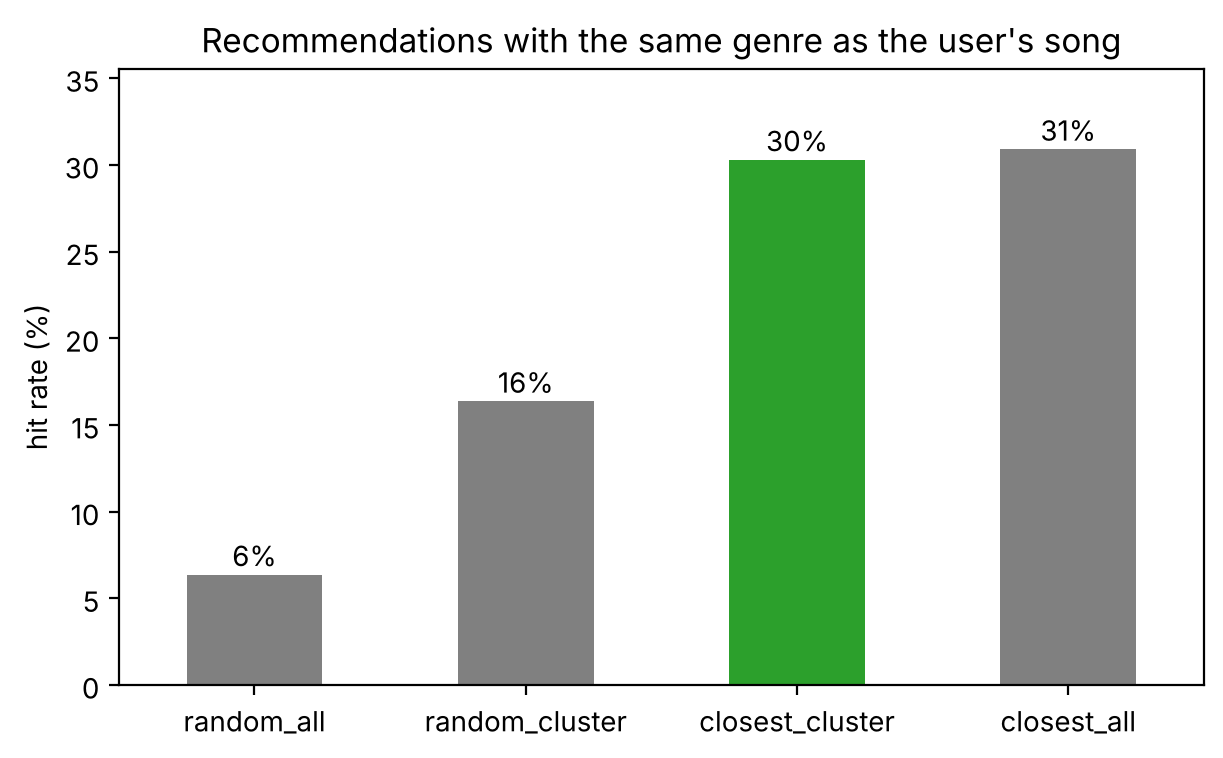

,hit_rate,vs_baseline
random_all,0.064,1.000
random_cluster,0.164,2.572
closest_cluster,0.303,4.762
closest_all,0.309,4.856


In [16]:
rng = np.random.default_rng(42)
clusters = songs["cluster"].values
genres = songs["genre"].values


def recommend_ids(i, n, method):
    candidates = np.delete(np.arange(len(songs)), i)
    if method.endswith("cluster"):
        candidates = candidates[clusters[candidates] == clusters[i]]
    if method.startswith("random"):
        return rng.choice(candidates, size=min(n, len(candidates)), replace=False)
    return candidates[np.argsort(D[i, candidates])[:n]]


def hit_rate(method, n=5):
    rates = [(genres[recommend_ids(i, n, method)] == genres[i]).mean()
             for i in range(len(songs)) if has_genre[i]]
    return np.mean(rates)


methods = ["random_all", "random_cluster", "closest_cluster", "closest_all"]
hit_rates = pd.DataFrame({"hit_rate": [hit_rate(m) for m in methods]}, index=methods)
hit_rates["vs_baseline"] = hit_rates["hit_rate"] / hit_rates.loc["random_all", "hit_rate"]

ax = (hit_rates["hit_rate"] * 100).plot(kind="bar", rot=0, figsize=(7, 4), color=["grey", "grey", "tab:green", "grey"],
                                        title="Recommendations with the same genre as the user's song")
ax.set_ylabel("hit rate (%)")
ax.set_ylim(0, hit_rates["hit_rate"].max() * 100 * 1.15)
for i, value in enumerate(hit_rates["hit_rate"] * 100):
    ax.text(i, value + 0.5, f"{value:.0f}%", ha="center")
plt.show()

hit_rates.round(3)

- **Baseline:** a random song has the same genre only ~6% of the time (pure chance with 15 genres).
- **Clusters alone** multiply that by 2.5 (16%).
- **Our recommender** (closest songs inside the cluster) reaches **30%: almost 5 times the baseline**.
- `closest_all` is about as good (31%), so why use clusters at all?
  1. **Speed at scale:** `closest_all` compares a song with *every* song in the catalogue. Fine for 1,200 songs, too slow for the millions Gnod wants. With clusters we compare with 7 centres first, then only with ~1/7 of the songs.
  2. **A product people understand:** clusters have names ("Soft & acoustic", "Loud & fast"), which gives explainable recommendations, mood filters and ready-made playlists for partner apps.
- **Caveat:** genre is only a proxy for "sounds similar". A "miss" can still sound right: *Bam Bam* (reggae) gets salsa and bossa nova songs from the same upbeat, danceable cluster.

## 8. Save the results for the app

The Streamlit app (`app.py`) reads this file, plus `data/popular_now.csv`: every song with its Deezer id (to play it), its audio features and its cluster.

In [17]:
columns = ["isrc", "deezer_id", "song", "artist", "genre"] + FEATURES + ["cluster", "cluster_name"]
songs[columns].to_csv(OUTPUT_FILE, index=False)
print(f"Saved {OUTPUT_FILE}: {len(songs)} songs")

Saved data/songs_clustered.csv: 1207 songs


## 9. Conclusions and next steps

**What we built**
- **Three data sources:** what's popular now from the **Deezer worldwide chart (API)** and the **Billboard Hot 100 (web scraping)**, and **1,207 songs with audio features** from 15 genres (Deezer + ReccoBeats APIs), working around Spotify's API restrictions.
- **7 clusters** of songs that sound alike, each with a clear description.
- A recommender that answers "popular right now" or "sounds like your song", and is **almost 5× better than random** at keeping the style, plus a **Streamlit app** to try it.

**Next steps**
1. **Grow the catalogue:** from 1,200 to millions of songs (more genres, more playlists, decades, countries), and refresh both charts **every week**, plus country charts for local recommendations.
2. **Songs we don't know yet:** look them up live (Deezer → ReccoBeats) and give them a cluster with `kmeans.predict`.
3. **Better recommendations:** mix the closest songs with a few random ones from the cluster for variety, and fix the weak clusters ("live recordings").
4. **Measure with real users:** A/B test the recommender against the current band recommender (clicks, songs played).
5. **Partnerships:** offer the clusters as mood playlists and the recommender as an API for music apps.